<a href="https://colab.research.google.com/github/mariayicellimon-design/r_hr-employee-attrition-prediction/blob/main/Predicci%C3%B3n_Drivers_Claude%20_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de Drivers (Tráfico, Conversión, Ticket Promedio) — versión corregida

**Qué se corrigió respecto a la versión anterior**

1. **Split temporal real.** Antes se ordenaba por `Unidad de Negocio` y luego `TimeSeriesSplit` cortaba por *posición de fila*, es decir por bloques de unidad: el train contenía fechas iguales y posteriores a las del test, y el fold 5 evaluaba unidades nunca vistas. Ahora los folds se definen por **fecha** (`train` < `test` para todas las unidades) y hay un `assert` que lo verifica.
2. **Lags/rollings sobre calendario completo.** Se construyen sobre una grilla fecha × unidad *antes* de cualquier recorte, y solo se descartan filas por NaN en los lags (no `dropna()` global).
3. **Simulación recursiva (cascada) correcta.** Arranca en el primer día del test de cada fold, se siembra con historia real previa, **oculta los valores reales del horizonte** y simula `HORIZONTE` días. El error se reporta **por horizonte** y contra un baseline ingenuo.
4. **Se separan dos evaluaciones con nombre claro:** *1 día adelante* (usa lags reales, "teacher forcing") y *multi-paso recursivo* (usa sus propias predicciones).
5. **Métricas comparables entre unidades** (WAPE) y baselines (`lag_1`, `lag_7`), porque el MAE y R² agrupados quedan dominados por eCommerce.
6. **Auditorías automáticas** de split, de la construcción de lags y de que el horizonte recursivo no ve datos reales.

> **Supuesto a validar:** las variables exógenas del mismo día (`Dias sin atencion`, `Dias con campaña`, `Descuento %`, calendario) se usan como **conocidas de antemano**. Si `Descuento %` es un valor *realizado* (no planificado), ponga `USAR_DESCUENTO = False`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import RandomForestRegressor

try:                                   # solo aplica en Colab
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

# ---------------- Configuración ----------------
FILE_PATH = '/content/drive/MyDrive/DBs/Drivers Históricos MC.xlsx'
SHEET     = 'sheet1'
DATE, UNIT = 'Calendar Date', 'Unidad de Negocio'
TARGETS   = ['Trafico', 'Conversion', 'Ticket Promedio']
N_SPLITS  = 5          # folds temporales
HORIZONTE = 100         # días de la simulación recursiva (por fold)
USAR_DESCUENTO = True  # False si 'Descuento %' NO se conoce de antemano
UNIDADES_GRAFICO = ['eCommerce', 'Sucursal Megacenter', 'Sucursal Oeste']

Mounted at /content/drive


In [ ]:
xl = pd.ExcelFile(FILE_PATH)
print("Hojas disponibles:", xl.sheet_names)
display(pd.read_excel(FILE_PATH, sheet_name=SHEET, nrows=5))

Hojas disponibles: ['sheet1']


,Calendar Date,Year,Month Number,Day Of Month,Day Of Week,Unidad de Negocio,Trafico,Conversion,Ticket Promedio,Dias sin atencion,Dias con campaña,Descuento %,Clientes Nuevos %
0,2024-01-01,2024,1,1,1,Sucursal Megacenter,310,0.845161,127.300382,0,0,0.112159,0.140428
1,2024-01-01,2024,1,1,1,Sucursal Norte,0,NaN,0.000000,1,0,0.108814,0.125894
2,2024-01-01,2024,1,1,1,Sucursal Oeste,0,NaN,86.920000,1,0,0.080283,0.158466
3,2024-01-01,2024,1,1,1,Sucursal Sucre,0,NaN,NaN,1,0,0.265656,0.326882
4,2024-01-01,2024,1,1,1,Sucursal Sur,2,0.000000,NaN,1,0,0.111029,0.094294


## 1. Carga, limpieza y grilla completa fecha × unidad
Se completa el calendario diario de cada unidad (desde su primer día hasta el último día del dataset) para que `shift(k)` signifique **exactamente k días**. La columna `existe` marca las filas que venían en el Excel.

In [ ]:
df = pd.read_excel(FILE_PATH, sheet_name=SHEET)
df[DATE] = pd.to_datetime(df[DATE])
assert not df.duplicated([DATE, UNIT]).any(), "Hay filas duplicadas (fecha, unidad)"

# Mismo tratamiento de nulos que antes (ver nota al final sobre este supuesto)
df[TARGETS] = df[TARGETS].fillna(0)
df['Is_Weekend'] = df['Day Of Week'].isin([6, 7]).astype(int)

units     = sorted(df[UNIT].unique())
all_dates = pd.date_range(df[DATE].min(), df[DATE].max(), freq='D')

grid  = pd.MultiIndex.from_product([all_dates, units], names=[DATE, UNIT])
panel = df.set_index([DATE, UNIT]).reindex(grid)
panel['existe'] = panel['Trafico'].notna()
panel = panel.reset_index().sort_values([UNIT, DATE]).reset_index(drop=True)

# Diagnóstico de huecos: días faltantes DESPUÉS del primer registro de cada unidad
primero = panel[panel['existe']].groupby(UNIT)[DATE].min()
huecos = panel.merge(primero.rename('primer_dia'), left_on=UNIT, right_index=True)
huecos = huecos[(huecos[DATE] >= huecos['primer_dia']) & (~huecos['existe'])]
print(f"Unidades: {len(units)} | Fechas: {all_dates[0].date()} → {all_dates[-1].date()} ({len(all_dates)} días)")
print("Primer registro por unidad:"); display(primero.to_frame('primer_dia'))
print(f"Días faltantes dentro del rango activo de cada unidad: {len(huecos)}")

Unidades: 13 | Fechas: 2024-01-01 → 2026-10-15 (1019 días)
Primer registro por unidad:


,primer_dia
Unidad de Negocio,
Call Center,2024-02-01
Sucursal Megacenter,2024-01-01
Sucursal Norte,2024-01-01
Sucursal Oeste,2024-01-01
Sucursal Sucre,2024-01-01
Sucursal Sur,2024-01-01
Sucursal Tarija,2024-01-01
Sucursal Uyuni,2024-01-01
Terminal 1 - Norte,2024-01-01


Días faltantes dentro del rango activo de cada unidad: 0


## 2. Features (solo pasado) y dataset de modelado
Lags 1/2/7 y medias móviles 3/7 **del lag 1** (idéntico al diseño original), calculados por unidad sobre la grilla completa. Las filas se descartan **solo** si sus lags/exógenas son NaN.

In [ ]:
EXOG = ['Year', 'Month Number', 'Day Of Month', 'Day Of Week',
        'Dias sin atencion', 'Dias con campaña', 'Is_Weekend']
if USAR_DESCUENTO:
    EXOG.append('Descuento %')

LAGS, ROLLS = [1, 2, 7], [3, 7]

LAG_FEATS = []
for c in TARGETS:
    g = panel.groupby(UNIT)[c]
    for k in LAGS:
        panel[f'{c}_lag_{k}'] = g.shift(k)
        LAG_FEATS.append(f'{c}_lag_{k}')
    for w in ROLLS:
        panel[f'{c}_roll_mean_{w}'] = panel.groupby(UNIT)[c].transform(lambda s: s.shift(1).rolling(w).mean())
        LAG_FEATS.append(f'{c}_roll_mean_{w}')

UNIT_COLS = [f'{UNIT}_{u}' for u in units]
for u, col in zip(units, UNIT_COLS):
    panel[col] = (panel[UNIT] == u).astype(float)

FEATURE_COLS = EXOG + LAG_FEATS + UNIT_COLS

valid = panel['existe'] & panel[LAG_FEATS].notna().all(axis=1) & panel[EXOG].notna().all(axis=1)
data = panel[valid].sort_values([DATE, UNIT]).reset_index(drop=True)   # orden CRONOLÓGICO

X = data[FEATURE_COLS].astype(float)
Y = data[TARGETS]
print(f"X: {X.shape} | Y: {Y.shape}")
print("Features:", FEATURE_COLS)

X: (12922, 36) | Y: (12922, 3)
Features: ['Year', 'Month Number', 'Day Of Month', 'Day Of Week', 'Dias sin atencion', 'Dias con campaña', 'Is_Weekend', 'Descuento %', 'Trafico_lag_1', 'Trafico_lag_2', 'Trafico_lag_7', 'Trafico_roll_mean_3', 'Trafico_roll_mean_7', 'Conversion_lag_1', 'Conversion_lag_2', 'Conversion_lag_7', 'Conversion_roll_mean_3', 'Conversion_roll_mean_7', 'Ticket Promedio_lag_1', 'Ticket Promedio_lag_2', 'Ticket Promedio_lag_7', 'Ticket Promedio_roll_mean_3', 'Ticket Promedio_roll_mean_7', 'Unidad de Negocio_Call Center', 'Unidad de Negocio_Sucursal Megacenter', 'Unidad de Negocio_Sucursal Norte', 'Unidad de Negocio_Sucursal Oeste', 'Unidad de Negocio_Sucursal Sucre', 'Unidad de Negocio_Sucursal Sur', 'Unidad de Negocio_Sucursal Tarija', 'Unidad de Negocio_Sucursal Uyuni', 'Unidad de Negocio_Terminal 1 - Norte', 'Unidad de Negocio_Terminal 1 - Oeste', 'Unidad de Negocio_Terminal 1 - Uyuni', 'Unidad de Negocio_Ventas Corporativas', 'Unidad de Negocio_eCommerce']


## 3. Folds temporales por FECHA
`TimeSeriesSplit` se aplica sobre el vector de **fechas únicas**, no sobre las filas. Cada fold tiene todas las unidades tanto en train como en test, y todo el train es anterior al test.

In [ ]:
fechas = pd.DatetimeIndex(np.sort(data[DATE].unique()))
folds = []
for k, (tr_d, te_d) in enumerate(TimeSeriesSplit(n_splits=N_SPLITS).split(fechas), start=1):
    cut, end = fechas[te_d[0]], fechas[te_d[-1]]
    tr = (data[DATE] < cut).to_numpy()
    te = ((data[DATE] >= cut) & (data[DATE] <= end)).to_numpy()
    # ---- AUDITORÍA DEL SPLIT ----
    assert data.loc[tr, DATE].max() < data.loc[te, DATE].min(), "¡El train llega a fechas del test!"
    folds.append(dict(k=k, cut=cut, end=end, tr=tr, te=te))
    print(f"Fold {k}: train {data.loc[tr, DATE].min().date()} → {data.loc[tr, DATE].max().date()} ({tr.sum()} filas) | "
          f"test {cut.date()} → {end.date()} ({te.sum()} filas, {data.loc[te, UNIT].nunique()} unidades)")
print("\n[OK] En todos los folds: max(fecha train) < min(fecha test)")

Fold 1: train 2024-01-08 → 2024-06-27 (2019 filas) | test 2024-06-28 → 2024-12-12 (2171 filas, 13 unidades)
Fold 2: train 2024-01-08 → 2024-12-12 (4190 filas) | test 2024-12-13 → 2025-05-29 (2184 filas, 13 unidades)
Fold 3: train 2024-01-08 → 2025-05-29 (6374 filas) | test 2025-05-30 → 2025-11-13 (2184 filas, 13 unidades)
Fold 4: train 2024-01-08 → 2025-11-13 (8558 filas) | test 2025-11-14 → 2026-04-30 (2184 filas, 13 unidades)
Fold 5: train 2024-01-08 → 2026-04-30 (10742 filas) | test 2026-05-01 → 2026-10-15 (2180 filas, 13 unidades)

[OK] En todos los folds: max(fecha train) < min(fecha test)


## 4. Matrices fecha × unidad y simulación recursiva
`features_step` calcula las features de un día **usando únicamente filas anteriores** de las matrices de targets. La misma función se usa (a) para auditar la construcción de lags y (b) dentro de la cascada, así no hay dos lógicas distintas.

In [ ]:
def _mat(col):
    return panel.pivot(index=DATE, columns=UNIT, values=col).reindex(index=all_dates, columns=units).to_numpy(float)

REAL  = {c: _mat(c) for c in TARGETS}                      # (fechas x unidades), valores reales
EXOGM = {c: _mat(c) for c in EXOG}                         # exógenas (asumidas conocidas de antemano)
EXIST = panel.pivot(index=DATE, columns=UNIT, values='existe').reindex(index=all_dates, columns=units)
EXIST = EXIST.astype(float).fillna(0).astype(bool).to_numpy()
EYE   = np.eye(len(units))
DIDX  = {d: i for i, d in enumerate(all_dates)}


def features_step(A, i):
    """Features del día i (todas las unidades). Lee SOLO A[...][<i] para los targets."""
    f = {c: EXOGM[c][i] for c in EXOG}
    for c in TARGETS:
        a = A[c]
        f[f'{c}_lag_1'], f[f'{c}_lag_2'], f[f'{c}_lag_7'] = a[i-1], a[i-2], a[i-7]
        f[f'{c}_roll_mean_3'] = a[i-3:i].mean(axis=0)
        f[f'{c}_roll_mean_7'] = a[i-7:i].mean(axis=0)
    for j, col in enumerate(UNIT_COLS):
        f[col] = EYE[:, j]
    F = pd.DataFrame(f)[FEATURE_COLS]
    ok = EXIST[i] & F.notna().all(axis=1).to_numpy()
    return F, ok


# ---- AUDITORÍA DE LAGS: features_step(real) debe coincidir con las features del dataset ----
rng = np.random.default_rng(0)
chequeos = 0
for d in rng.choice(fechas.values, size=25, replace=False):
    d = pd.Timestamp(d)
    F, ok = features_step(REAL, DIDX[d])
    sub = data[data[DATE] == d]
    if sub.empty:
        continue
    j = [units.index(u) for u in sub[UNIT]]
    assert np.allclose(F.iloc[j].to_numpy(float), sub[FEATURE_COLS].to_numpy(float), equal_nan=True), f"Lags inconsistentes en {d.date()}"
    chequeos += 1
print(f"[OK] Construcción de lags consistente en {chequeos} fechas aleatorias (groupby/shift == features_step)")


def make_model():
    return MultiOutputRegressor(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))


def simular_recursivo(model, cut, H):
    """Cascada: desde `cut` predice H días; cada predicción alimenta los lags del día siguiente.
    Los valores reales desde `cut` en adelante se OCULTAN (NaN) antes de simular."""
    i0 = DIDX[cut]
    i1 = min(i0 + H, len(all_dates))
    A = {c: REAL[c].copy() for c in TARGETS}
    for c in TARGETS:
        A[c][i0:] = np.nan
    assert all(np.isnan(A[c][i0:]).all() for c in TARGETS)   # el horizonte no ve datos reales
    for i in range(i0, i1):
        F, ok = features_step(A, i)
        if ok.any():
            P = model.predict(F.loc[ok, FEATURE_COLS])
            for k, c in enumerate(TARGETS):
                A[c][i, ok] = P[:, k]
    return A, i0, i1


def wape(y, p):
    return np.abs(y - p).sum() / max(np.abs(y).sum(), 1e-9)


def errores_por_horizonte(A, i0, i1):
    """WAPE y MAE por día de horizonte (h=1..H): modelo recursivo vs baseline estacional (mismo día de la
    semana en la última semana REAL antes del origen)."""
    H = i1 - i0
    out = {m: np.full((H, len(TARGETS)), np.nan) for m in ['wape_mod', 'wape_base', 'mae_mod', 'mae_base']}
    for h in range(H):
        k = int(np.ceil((h + 1) / 7))
        i_base = i0 + h - 7 * k                    # siempre < i0 → solo historia real
        for t, c in enumerate(TARGETS):
            y, p = REAL[c][i0 + h], A[c][i0 + h]
            b = REAL[c][i_base]
            m = EXIST[i0 + h] & np.isfinite(y) & np.isfinite(p) & np.isfinite(b)
            if m.any():
                out['wape_mod'][h, t]  = wape(y[m], p[m]);  out['mae_mod'][h, t]  = np.abs(y[m] - p[m]).mean()
                out['wape_base'][h, t] = wape(y[m], b[m]);  out['mae_base'][h, t] = np.abs(y[m] - b[m]).mean()
    return out

[OK] Construcción de lags consistente en 25 fechas aleatorias (groupby/shift == features_step)


## 5. Entrenamiento y evaluación por fold
En cada fold: se entrena **solo con fechas < inicio del test** y se evalúa (a) **1 día adelante** sobre todo el periodo de test y (b) **cascada** de `HORIZONTE` días desde el primer día del test.

In [ ]:
res_1step, res_rec, store = [], [], {}

for f in folds:
    k, tr, te = f['k'], f['tr'], f['te']
    model = make_model().fit(X[tr], Y[tr])

    # (a) 1 día adelante (usa lags REALES del periodo de test → teacher forcing)
    P = model.predict(X[te])
    for t, c in enumerate(TARGETS):
        y = Y.loc[te, c].to_numpy()
        l1 = X.loc[te, f'{c}_lag_1'].to_numpy()
        l7 = X.loc[te, f'{c}_lag_7'].to_numpy()
        res_1step.append(dict(fold=k, target=c,
                              MAE_modelo=np.abs(y - P[:, t]).mean(), WAPE_modelo=wape(y, P[:, t]),
                              WAPE_lag1=wape(y, l1), WAPE_lag7=wape(y, l7)))

    # (b) multi-paso recursivo
    H = min(HORIZONTE, (f['end'] - f['cut']).days + 1)
    A, i0, i1 = simular_recursivo(model, f['cut'], H)
    res_rec.append(dict(fold=k, **errores_por_horizonte(A, i0, i1)))

    store[k] = dict(model=model, P=P, A=A, i0=i0, i1=i1)
    print(f"Fold {k} listo")

r1 = pd.DataFrame(res_1step)
print("\n=== 1 DÍA ADELANTE (usa lags reales) — WAPE: menor es mejor ===")
display(r1.round(4))
print("Promedio sobre folds:")
display(r1.groupby('target')[['MAE_modelo', 'WAPE_modelo', 'WAPE_lag1', 'WAPE_lag7']].mean().round(4))

Fold 1 listo
Fold 2 listo
Fold 3 listo
Fold 4 listo
Fold 5 listo

=== 1 DÍA ADELANTE (usa lags reales) — WAPE: menor es mejor ===


,fold,target,MAE_modelo,WAPE_modelo,WAPE_lag1,WAPE_lag7
0,1,Trafico,238.6532,0.1859,0.2074,0.3050
1,1,Conversion,0.0264,0.1717,0.2934,0.2161
2,1,Ticket Promedio,545.6029,0.7138,0.9290,0.9613
3,2,Trafico,262.7336,0.1933,0.2208,0.2905
4,2,Conversion,0.0241,0.1598,0.3378,0.2384
5,2,Ticket Promedio,462.3047,0.7578,0.8859,0.8306
6,3,Trafico,237.6952,0.1741,0.2276,0.3047
7,3,Conversion,0.0263,0.1738,0.3386,0.2573
8,3,Ticket Promedio,593.9262,0.9393,0.7166,0.6466
9,4,Trafico,440.5405,0.2446,0.2559,0.4168


Promedio sobre folds:


,MAE_modelo,WAPE_modelo,WAPE_lag1,WAPE_lag7
target,,,,
Conversion,0.0349,0.2141,0.3680,0.2993
Ticket Promedio,556.9212,0.7853,0.8547,0.8257
Trafico,301.9918,0.1999,0.2345,0.3348


=== CASCADA — WAPE por horizonte (promedio de folds) ===


Recursivo                                \
       Trafico    Conversion Ticket Promedio   
h=1     0.2534  1.052800e+00    4.821800e+00   
h=3     0.4042  6.621659e+07    5.529570e+11   
h=7     0.2319  1.521000e-01    6.870000e-01   
h=14    0.1590  1.269000e-01    8.504000e-01   
h=21    0.5985  4.005000e-01    6.235000e-01   
h=30    0.5883  6.199000e-01    5.474000e-01   

     Baseline (misma weekday sem. previa)                                
                                  Trafico    Conversion Ticket Promedio  
h=1                                0.4713  3.226400e+00    4.249400e+00  
h=3                                0.5793  2.153492e+08    6.001887e+11  
h=7                                0.2648  1.545000e-01    7.987000e-01  
h=14                               0.2080  1.606000e-01    1.542400e+00  
h=21                               0.5091  4.669000e-01    9.199000e-01  
h=30                               0.6456  4.128000e-01    7.746000e-01

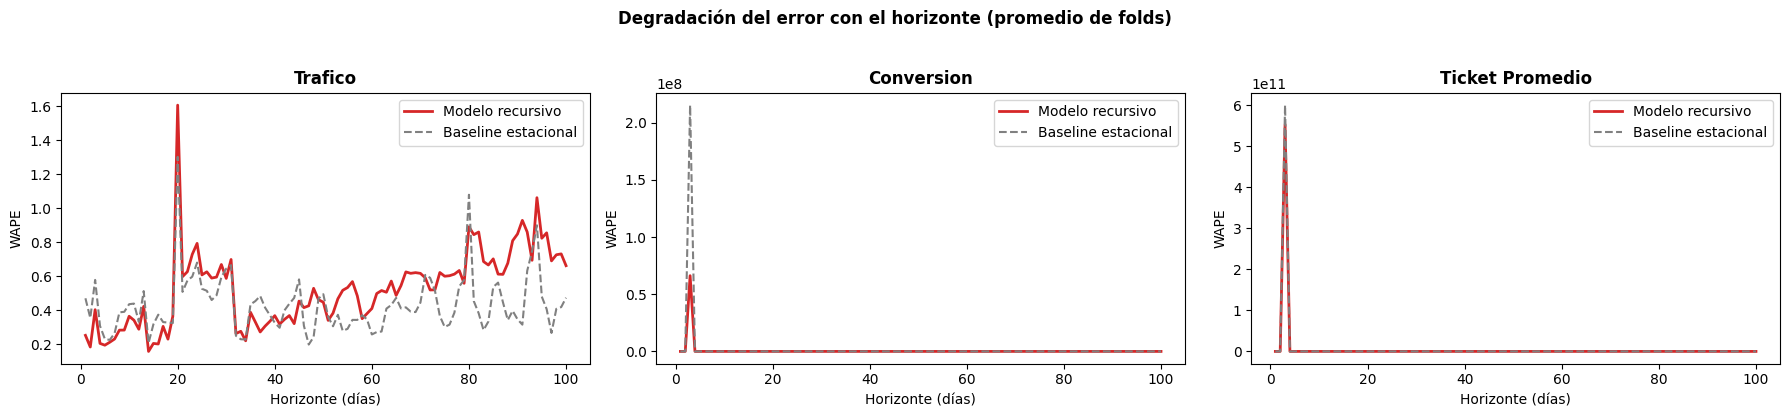

In [ ]:
# ---- Error de la CASCADA por horizonte (promedio de folds) ----
H_min = min(r['wape_mod'].shape[0] for r in res_rec)
wm = np.nanmean([r['wape_mod'][:H_min]  for r in res_rec], axis=0)
wb = np.nanmean([r['wape_base'][:H_min] for r in res_rec], axis=0)

hs = [h for h in (1, 3, 7, 14, 21, 30) if h <= H_min]
tab = pd.concat({
    'Recursivo': pd.DataFrame(wm[[h-1 for h in hs]], index=[f'h={h}' for h in hs], columns=TARGETS),
    'Baseline (misma weekday sem. previa)': pd.DataFrame(wb[[h-1 for h in hs]], index=[f'h={h}' for h in hs], columns=TARGETS),
}, axis=1)
print("=== CASCADA — WAPE por horizonte (promedio de folds) ===")
display(tab.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for t, c in enumerate(TARGETS):
    axes[t].plot(range(1, H_min + 1), wm[:, t], label='Modelo recursivo', color='#d62728', linewidth=2)
    axes[t].plot(range(1, H_min + 1), wb[:, t], label='Baseline estacional', color='gray', linestyle='--')
    axes[t].set_title(c, fontweight='bold'); axes[t].set_xlabel('Horizonte (días)'); axes[t].set_ylabel('WAPE')
    axes[t].legend()
plt.suptitle('Degradación del error con el horizonte (promedio de folds)', fontweight='bold', y=1.03)
plt.tight_layout(); plt.show()

## 6. Gráficos (último fold, periodo de test)
**Fila superior de cada bloque:** 1 día adelante (lags reales). **Segundo bloque:** cascada de `HORIZONTE` días con sus propias predicciones.

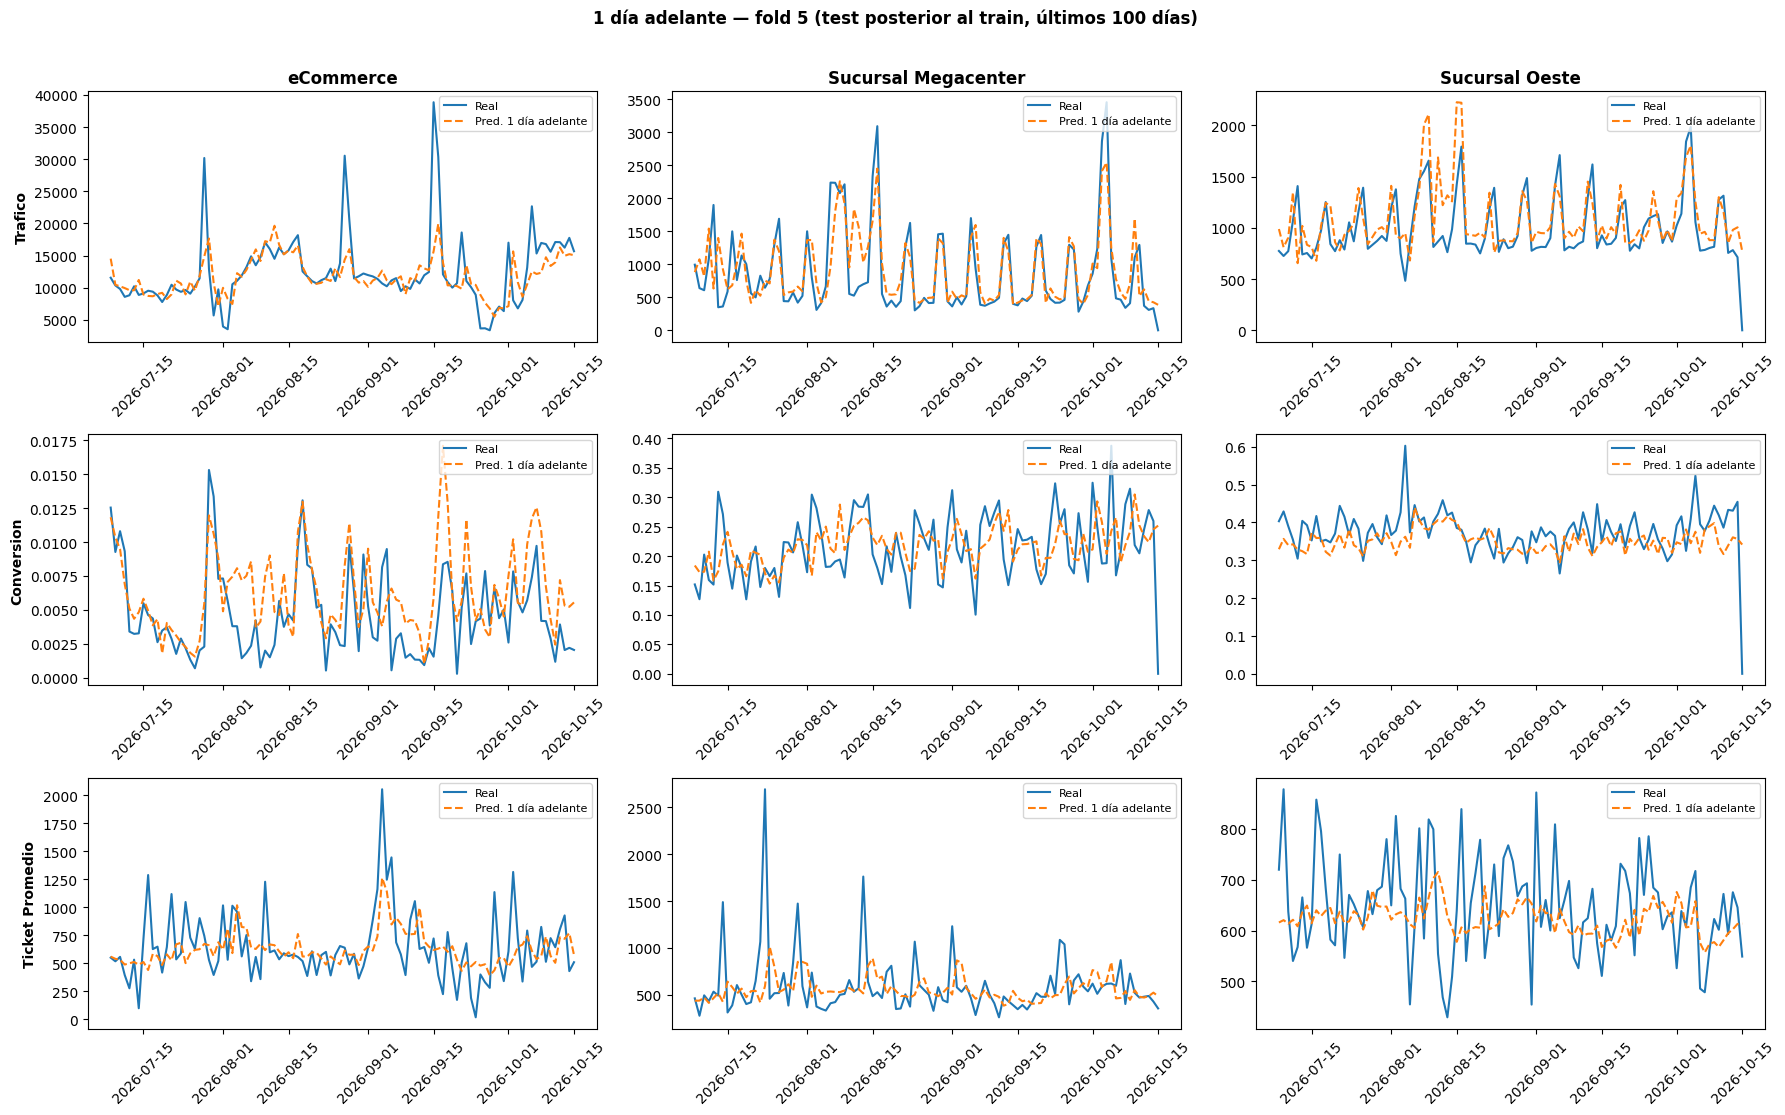

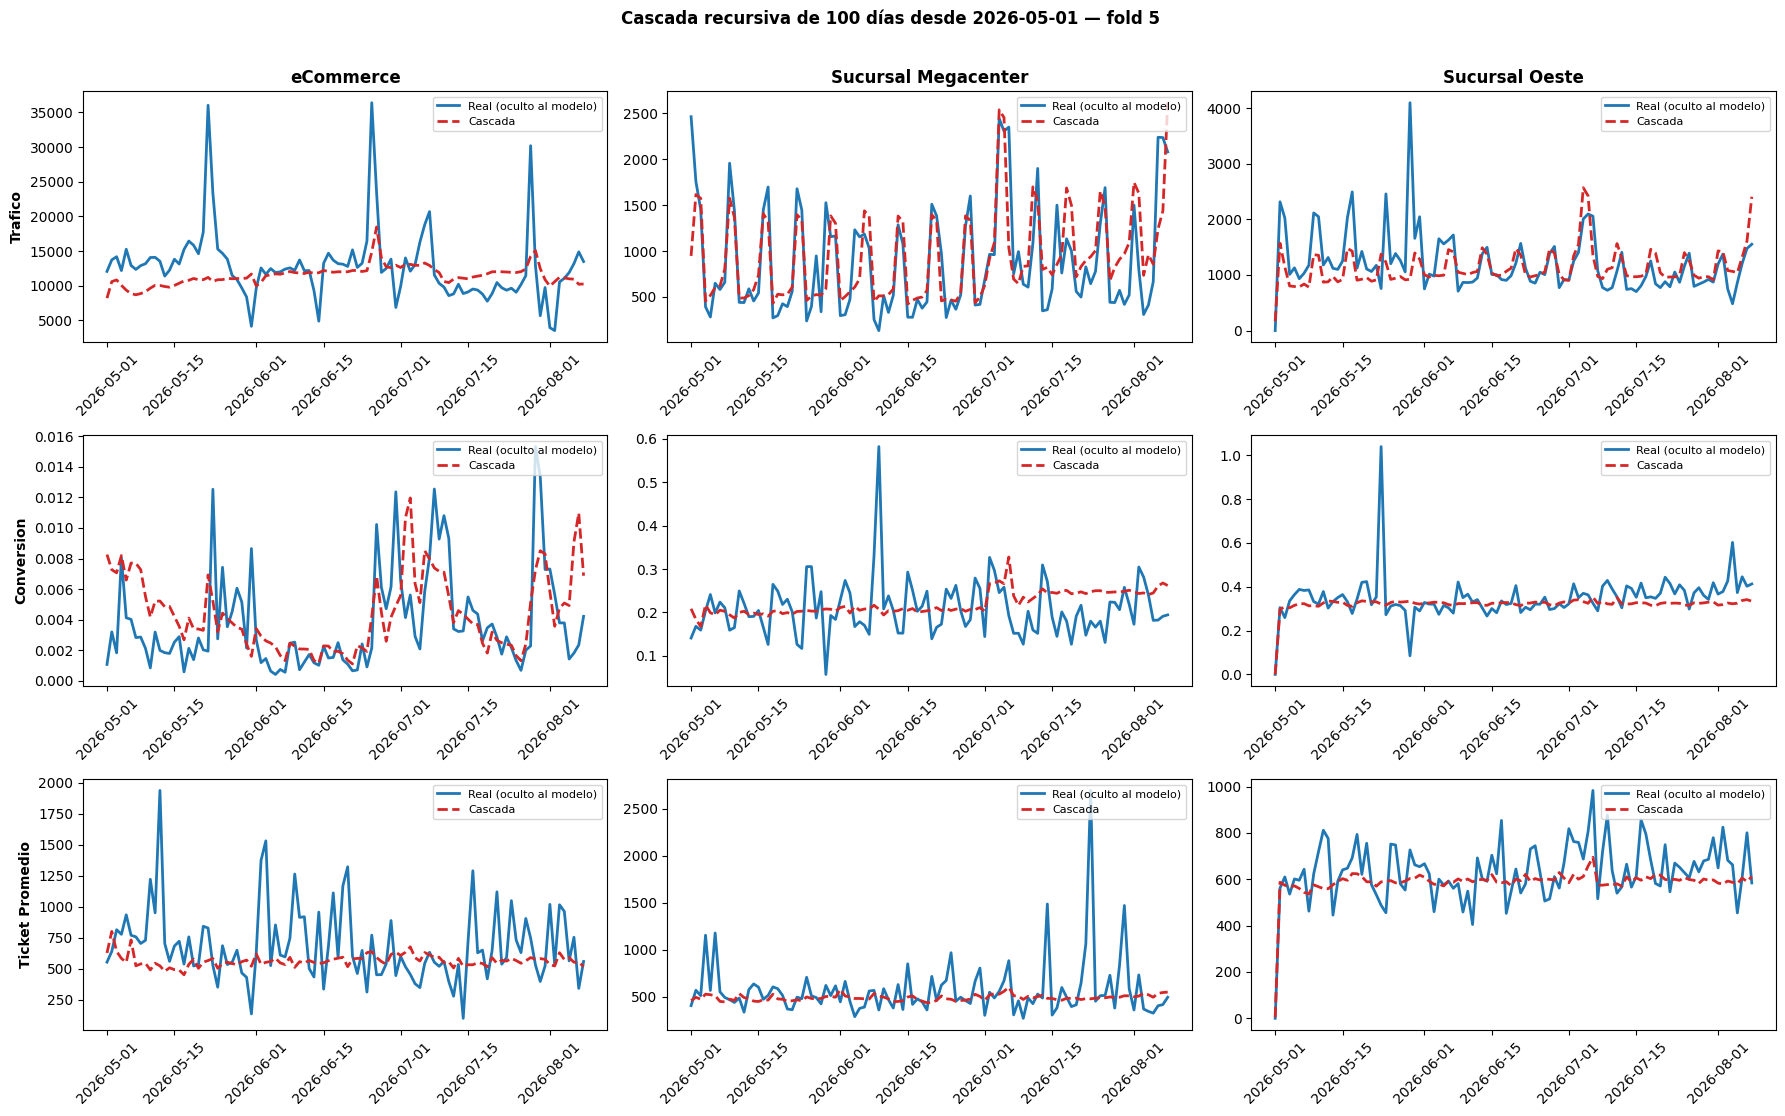

WAPE 1 día adelante por unidad (último fold):


,WAPE Trafico,WAPE Conversion,WAPE Ticket Promedio
Unidad,,,
Call Center,0.246,0.927,0.898
Sucursal Megacenter,0.297,0.206,0.302
Sucursal Norte,0.190,0.144,0.128
Sucursal Oeste,0.218,0.124,0.125
Sucursal Sucre,0.272,0.170,0.426
Sucursal Sur,0.288,0.693,0.247
Sucursal Tarija,0.215,0.195,0.360
Sucursal Uyuni,0.249,0.159,0.170
Terminal 1 - Norte,0.194,0.319,0.316


In [ ]:
f5 = folds[-1]
te5 = f5['te']
d5 = data.loc[te5, [DATE, UNIT]].copy()
for t, c in enumerate(TARGETS):
    d5[f'{c}_Real'] = Y.loc[te5, c].to_numpy()
    d5[f'{c}_Pred'] = store[f5['k']]['P'][:, t]

ejemplos = [u for u in UNIDADES_GRAFICO if u in units] or units[:3]
fig, axes = plt.subplots(len(TARGETS), len(ejemplos), figsize=(6 * len(ejemplos), 11), squeeze=False)
for j, u in enumerate(ejemplos):
    du = d5[d5[UNIT] == u].sort_values(DATE).tail(100)
    for i, c in enumerate(TARGETS):
        ax = axes[i, j]
        ax.plot(du[DATE], du[f'{c}_Real'], label='Real', color='#1f77b4', linewidth=1.5)
        ax.plot(du[DATE], du[f'{c}_Pred'], label='Pred. 1 día adelante', color='#ff7f0e', linestyle='--', linewidth=1.5)
        if i == 0: ax.set_title(u, fontweight='bold')
        if j == 0: ax.set_ylabel(c, fontweight='bold')
        ax.tick_params(axis='x', rotation=45); ax.legend(loc='upper right', fontsize=8)
plt.suptitle(f'1 día adelante — fold {f5["k"]} (test posterior al train, últimos 100 días)', fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

# ---- Cascada del último fold ----
s = store[f5['k']]
fig, axes = plt.subplots(len(TARGETS), len(ejemplos), figsize=(6 * len(ejemplos), 11), squeeze=False)
idx = all_dates[s['i0']:s['i1']]
for j, u in enumerate(ejemplos):
    ju = units.index(u)
    for i, c in enumerate(TARGETS):
        ax = axes[i, j]
        ax.plot(idx, REAL[c][s['i0']:s['i1'], ju], label='Real (oculto al modelo)', color='#1f77b4', linewidth=2)
        ax.plot(idx, s['A'][c][s['i0']:s['i1'], ju], label='Cascada', color='#d62728', linestyle='--', linewidth=2)
        if i == 0: ax.set_title(u, fontweight='bold')
        if j == 0: ax.set_ylabel(c, fontweight='bold')
        ax.tick_params(axis='x', rotation=45); ax.legend(loc='upper right', fontsize=8)
plt.suptitle(f'Cascada recursiva de {s["i1"]-s["i0"]} días desde {all_dates[s["i0"]].date()} — fold {f5["k"]}', fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

# ---- WAPE por unidad (1 día adelante, último fold) ----
filas = []
for u in units:
    du = d5[d5[UNIT] == u]
    if len(du):
        filas.append({'Unidad': u, **{f'WAPE {c}': wape(du[f'{c}_Real'].to_numpy(), du[f'{c}_Pred'].to_numpy()) for c in TARGETS}})
print("WAPE 1 día adelante por unidad (último fold):")
display(pd.DataFrame(filas).set_index('Unidad').round(3))

## 7. Sensibilidad: ¿cuánto depende el resultado de `Descuento %`?
Si `Descuento %` no se conoce antes del día a pronosticar, este cuadro muestra cuánto del desempeño viene de esa variable (último fold, 1 día adelante).

In [ ]:
def wape_fold(cols, f):
    m = make_model().fit(X.loc[f['tr'], cols], Y[f['tr']])
    P = m.predict(X.loc[f['te'], cols])
    return {c: wape(Y.loc[f['te'], c].to_numpy(), P[:, t]) for t, c in enumerate(TARGETS)}

con = FEATURE_COLS
sin = [c for c in FEATURE_COLS if c != 'Descuento %']
comp = {'Con Descuento %': wape_fold(con, folds[-1])}
if 'Descuento %' in FEATURE_COLS:
    comp['Sin Descuento %'] = wape_fold(sin, folds[-1])
print("WAPE (último fold, 1 día adelante):")
display(pd.DataFrame(comp).T.round(4))

WAPE (último fold, 1 día adelante):


,Trafico,Conversion,Ticket Promedio
Con Descuento %,0.2015,0.2722,0.7539
Sin Descuento %,0.2010,0.2729,0.7868


## 8. Correlaciones (solo con datos de entrenamiento del último fold)
Descriptivo. Se calcula únicamente con el train del último fold para que no se use información del test en ninguna decisión de features.

In [ ]:
tr5 = folds[-1]['tr']
corr = pd.concat([X[tr5], Y[tr5]], axis=1).corr()[TARGETS].drop(index=TARGETS)
display(corr.sort_values('Trafico', ascending=False).round(3))

,Trafico,Conversion,Ticket Promedio
Trafico_lag_1,0.924,-0.246,-0.026
Trafico_roll_mean_3,0.915,-0.254,-0.027
Trafico_roll_mean_7,0.906,-0.262,-0.028
Trafico_lag_2,0.877,-0.246,-0.026
Unidad de Negocio_eCommerce,0.834,-0.239,-0.016
Trafico_lag_7,0.832,-0.249,-0.027
Descuento %,0.253,0.156,0.030
Dias con campaña,0.182,0.063,-0.013
Year,0.051,-0.023,0.021
Is_Weekend,0.051,-0.088,-0.044


## Cómo leer los resultados y limitaciones que quedan

- **1 día adelante** responde: *"si mañana ya conozco lo de hoy, ¿qué tan bien predigo mañana?"*. Es optimista porque usa lags reales; compárelo siempre con `WAPE_lag1` y `WAPE_lag7` (si el modelo no los supera, no aporta).
- **Cascada** responde: *"¿qué tan bien pronostico 30 días hacia adelante sin conocer nada de ese periodo?"*. Es la medida honesta de un forecast; el error debería crecer con el horizonte. Compárelo con el baseline estacional.
- Las **exógenas del día objetivo** (`Dias sin atencion`, `Dias con campaña`, `Descuento %`, calendario) se toman del dato real: solo son válidas si se conocen antes del periodo a pronosticar.
- **`fillna(0)` de Conversión y Ticket**: se mantuvo por compatibilidad, pero un día sin tráfico no tiene conversión 0 sino *indefinida*. Esto introduce ceros artificiales en targets y lags; una mejora es modelar Conversión y Ticket solo en días con atención y tráfico > 0 (o con un modelo en dos etapas).
- **Escala distinta por unidad** (eCommerce ≫ resto): considere entrenar con el target en log o por unidad, y reporte siempre WAPE/por unidad en lugar de R² agrupado.

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files

def simular_recursivo_con_reglas(model, cut, H):
    """Simulación recursiva que aplica las reglas de negocio de tráfico en cada paso "i"
    para que impacte correctamente en los lags de los días siguientes (propagándose a Conversión y Ticket)."""
    i0 = DIDX[cut]
    i1 = min(i0 + H, len(all_dates))

    # Copiamos la matriz real y ocultamos el horizonte de test
    A = {c: REAL[c].copy() for c in TARGETS}
    for c in TARGETS:
        A[c][i0:] = np.nan

    # Identificamos índices de las unidades involucradas para mapeo rápido
    idx_o_suc = units.index('Sucursal Oeste')
    idx_o_term = units.index('Terminal 1 - Oeste')
    idx_n_suc = units.index('Sucursal Norte')
    idx_n_term = units.index('Terminal 1 - Norte')
    idx_u_suc = units.index('Sucursal Uyuni')
    idx_u_term = units.index('Terminal 1 - Uyuni')
    idx_corp = units.index('Ventas Corporativas')

    # Diccionario para acumular dinámicamente el tráfico mensual de Ventas Corporativas y promediarlo al final del mes
    # Sin embargo, como la simulación corre día a día hacia adelante y los lags dependen del pasado,
    # para hacerlo 100% fiel en cascada sin mirar el futuro, aplicamos las reglas de sincronización de Terminales día a día:

    for i in range(i0, i1):
        # 1. Generar features para el día i basadas en el pasado A[...][:i]
        F, ok = features_step(A, i)

        # 2. Predecir Targets (Tráfico, Conversión, Ticket Promedio)
        if ok.any():
            P = model.predict(F.loc[ok, FEATURE_COLS])
            for k, c in enumerate(TARGETS):
                A[c][i, ok] = P[:, k]

            # 3. Aplicar Regla de Sincronización Inmediata de Terminales (Tráfico día i)
            # Terminal Oeste = Sucursal Oeste
            if EXIST[i, idx_o_term] and EXIST[i, idx_o_suc]:
                A['Trafico'][i, idx_o_term] = A['Trafico'][i, idx_o_suc]
            # Terminal Norte = Sucursal Norte
            if EXIST[i, idx_n_term] and EXIST[i, idx_n_suc]:
                A['Trafico'][i, idx_n_term] = A['Trafico'][i, idx_n_suc]
            # Terminal Uyuni = Sucursal Uyuni
            if EXIST[i, idx_u_term] and EXIST[i, idx_u_suc]:
                A['Trafico'][i, idx_u_term] = A['Trafico'][i, idx_u_suc]

    # 4. Regla de Ventas Corporativas (Tráfico constante durante el mes)
    # Al terminar la simulación, agrupamos el tráfico de Ventas Corporativas por mes, promediamos y sobreescribimos en A
    fechas_simuladas = all_dates[i0:i1]
    meses_unicos = sorted(list(set(f.to_period('M') for f in fechas_simuladas)))

    for mes in meses_unicos:
        indices_mes = [idx for idx, f in enumerate(fechas_simuladas) if f.to_period('M') == mes]
        indices_reales = [i0 + idx for idx in indices_mes]

        valores_trafico = [A['Trafico'][idx, idx_corp] for idx in indices_reales if EXIST[idx, idx_corp] and not np.isnan(A['Trafico'][idx, idx_corp])]
        if valores_trafico:
            promedio_mes = np.mean(valores_trafico)
            for idx in indices_reales:
                if EXIST[idx, idx_corp]:
                    A['Trafico'][idx, idx_corp] = promedio_mes

    return A, i0, i1

# --- Ejecutamos la simulación con el modelo entrenado del último fold (fold 5) ---
f5 = folds[-1]
model_f5 = store[f5['k']]['model']
H5 = min(HORIZONTE, (f5['end'] - f5['cut']).days + 1)

A_corregido, i0_5, i1_5 = simular_recursivo_con_reglas(model_f5, f5['cut'], H5)
fechas_horizonte = all_dates[i0_5:i1_5]

# Estructuramos el DataFrame final a exportar
filas_predicciones = []
for idx_fecha, fecha in enumerate(fechas_horizonte):
    i_real = i0_5 + idx_fecha
    for idx_unidad, unidad in enumerate(units):
        if EXIST[i_real, idx_unidad]:
            registro = {
                'Fecha': fecha.strftime('%Y-%m-%d'),
                'Unidad de Negocio': unidad
            }
            for target in TARGETS:
                registro[f'{target}_Pred_Cascada'] = A_corregido[target][i_real, idx_unidad]
            filas_predicciones.append(registro)

df_predicciones = pd.DataFrame(filas_predicciones)

# Exportamos a CSV delimitado por (;) y con decimales como (,)
nombre_archivo = 'predicciones_cascada.csv'
df_predicciones.to_csv(nombre_archivo, sep=';', decimal=',', index=False, encoding='utf-8-sig')

print(f"Archivo '{nombre_archivo}' generado exitosamente con el impacto dinámico en cascada. Iniciando descarga...")
files.download(nombre_archivo)

Archivo 'predicciones_cascada.csv' generado exitosamente con el impacto dinámico en cascada. Iniciando descarga...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>